In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

Train Data

In [2]:
# load training dataset

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

columns = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status", "occupation",
           "relationship", "race", "sex", "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]

ds_train = pd.read_csv(url, names=columns, na_values=" ?", skipinitialspace=True)
print(ds_train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB
None


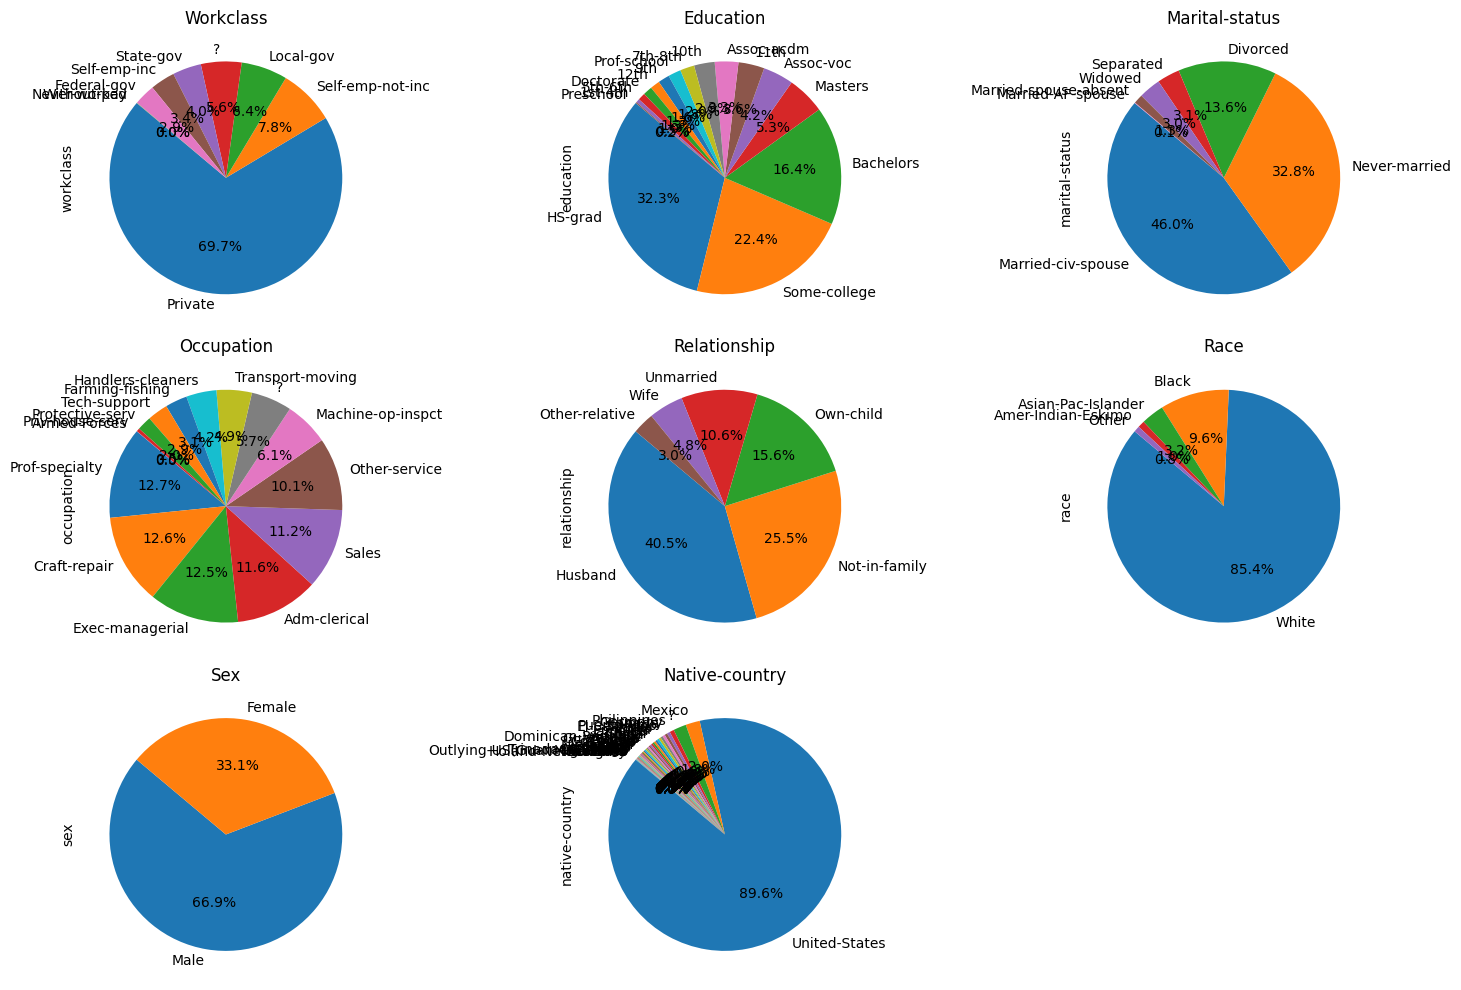

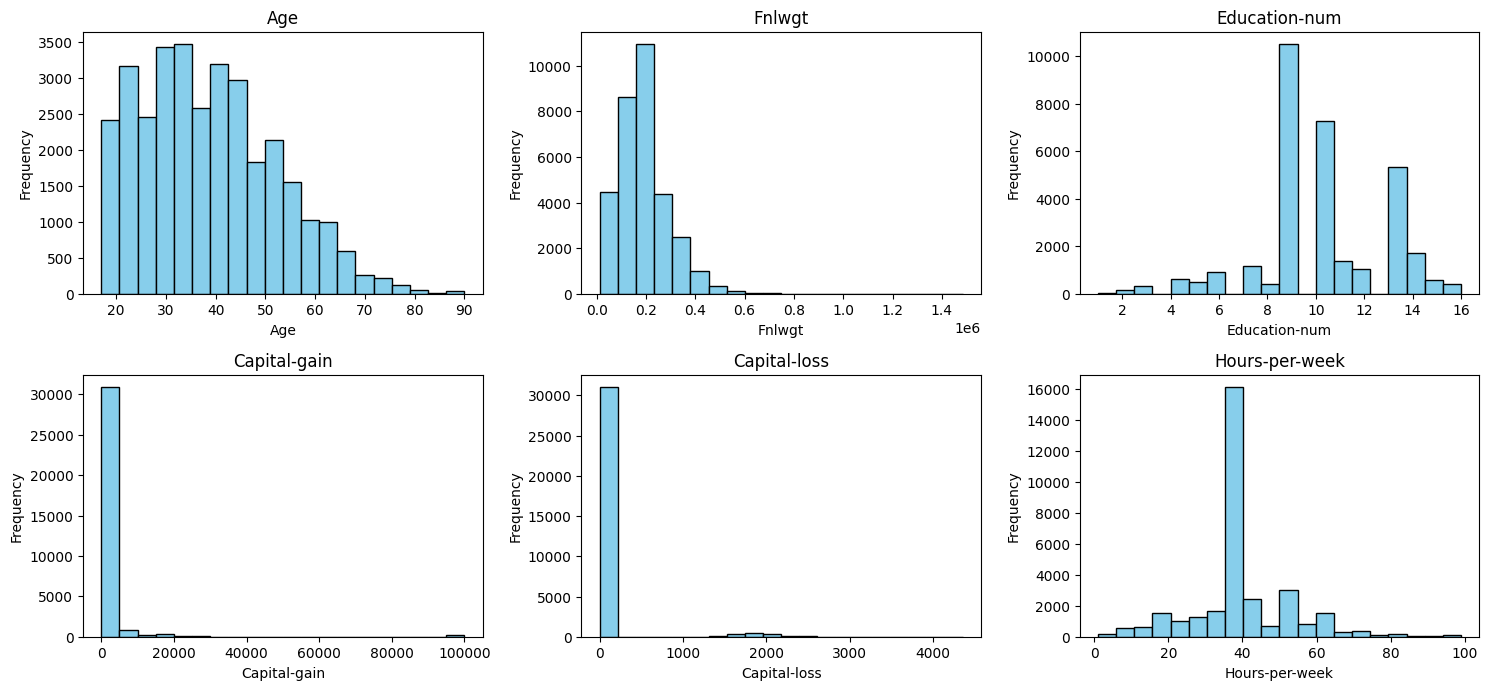

In [3]:
import matplotlib.pyplot as plt

# Pie charts for categorical features
categorical_features = ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

plt.figure(figsize=(15, 10))
for i, feature in enumerate(categorical_features, 1):
    plt.subplot(3, 3, i)
    ds_train[feature].value_counts().plot.pie(autopct='%1.1f%%', startangle=140)
    plt.title(feature.capitalize().replace('_', ' '))
plt.tight_layout()
plt.show()

# Histograms for continuous features
numerical_features = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

plt.figure(figsize=(15, 10))
for i, feature in enumerate(numerical_features, 1):
    plt.subplot(3, 3, i)
    plt.hist(ds_train[feature], bins=20, color='skyblue', edgecolor='black')
    plt.title(feature.capitalize().replace('_', ' '))
    plt.xlabel(feature.capitalize().replace('_', ' '))
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


In [4]:
# cleaning
import numpy as np
from scipy import stats

# missing values
ds_train.dropna(inplace=True)

# duplicate entries
ds_train.drop_duplicates(inplace=True)

# converting to lowercase
ds_train = ds_train.apply(lambda x: x.str.lower() if x.dtype == "object" else x)

# Remove outliers in 'age' feature
ds_train = ds_train[(np.abs(stats.zscore(ds_train['age'])) < 3)]

print(ds_train.info())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 32417 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32417 non-null  int64 
 1   workclass       32417 non-null  object
 2   fnlwgt          32417 non-null  int64 
 3   education       32417 non-null  object
 4   education-num   32417 non-null  int64 
 5   marital-status  32417 non-null  object
 6   occupation      32417 non-null  object
 7   relationship    32417 non-null  object
 8   race            32417 non-null  object
 9   sex             32417 non-null  object
 10  capital-gain    32417 non-null  int64 
 11  capital-loss    32417 non-null  int64 
 12  hours-per-week  32417 non-null  int64 
 13  native-country  32417 non-null  object
 14  income          32417 non-null  object
dtypes: int64(6), object(9)
memory usage: 4.0+ MB
None


In [5]:
# feature engineering

#seperating categorical features
categorical_features = list(ds_train.select_dtypes(include=['object']).columns)
print(categorical_features)

#seperating numerical features
numerical_features = list(ds_train.select_dtypes(include=['int64', 'float64']).columns)
print(numerical_features)

print(ds_train.head())

['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country', 'income']
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
   age         workclass  fnlwgt  education  education-num  \
0   39         state-gov   77516  bachelors             13   
1   50  self-emp-not-inc   83311  bachelors             13   
2   38           private  215646    hs-grad              9   
3   53           private  234721       11th              7   
4   28           private  338409  bachelors             13   

       marital-status         occupation   relationship   race     sex  \
0       never-married       adm-clerical  not-in-family  white    male   
1  married-civ-spouse    exec-managerial        husband  white    male   
2            divorced  handlers-cleaners  not-in-family  white    male   
3  married-civ-spouse  handlers-cleaners        husband  black    male   
4  married-civ-spouse     prof-specialty           wif

Test Data

In [6]:
# load testing dataset

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

columns = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status", "occupation",
           "relationship", "race", "sex", "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]

ds_test = pd.read_csv(url, names=columns, na_values=" ?", skipinitialspace=True, skiprows=1) # avoiding "|1x3 Cross validator" string
print(ds_test.info())
print(ds_test.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16281 entries, 0 to 16280
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             16281 non-null  int64 
 1   workclass       16281 non-null  object
 2   fnlwgt          16281 non-null  int64 
 3   education       16281 non-null  object
 4   education-num   16281 non-null  int64 
 5   marital-status  16281 non-null  object
 6   occupation      16281 non-null  object
 7   relationship    16281 non-null  object
 8   race            16281 non-null  object
 9   sex             16281 non-null  object
 10  capital-gain    16281 non-null  int64 
 11  capital-loss    16281 non-null  int64 
 12  hours-per-week  16281 non-null  int64 
 13  native-country  16281 non-null  object
 14  income          16281 non-null  object
dtypes: int64(6), object(9)
memory usage: 1.9+ MB
None
   age  workclass  fnlwgt     education  education-num      marital-status  \
0   25    

In [7]:
# cleaning
import numpy as np
from scipy import stats

# convert false dtypes
ds_test['age'] = ds_test['age'].astype(int)
ds_test['fnlwgt'] = ds_test['fnlwgt'].astype(int)
ds_test['education-num'] = ds_test['education-num'].astype(int)
ds_test['capital-gain'] = ds_test['capital-gain'].astype(int)
ds_test['capital-loss'] = ds_test['capital-loss'].astype(int)
ds_test['hours-per-week'] = ds_test['hours-per-week'].astype(int)

# missing values
ds_test.dropna(inplace=True)

# duplicate entries
ds_test.drop_duplicates(inplace=True)

# converting to lowercase
ds_test = ds_test.apply(lambda x: x.str.lower() if x.dtype == "object" else x)

# Remove outliers in 'age' feature
ds_test = ds_test[(np.abs(stats.zscore(ds_test['age'])) < 3)]

print(ds_test.info())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 16227 entries, 0 to 16280
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             16227 non-null  int64 
 1   workclass       16227 non-null  object
 2   fnlwgt          16227 non-null  int64 
 3   education       16227 non-null  object
 4   education-num   16227 non-null  int64 
 5   marital-status  16227 non-null  object
 6   occupation      16227 non-null  object
 7   relationship    16227 non-null  object
 8   race            16227 non-null  object
 9   sex             16227 non-null  object
 10  capital-gain    16227 non-null  int64 
 11  capital-loss    16227 non-null  int64 
 12  hours-per-week  16227 non-null  int64 
 13  native-country  16227 non-null  object
 14  income          16227 non-null  object
dtypes: int64(6), object(9)
memory usage: 2.0+ MB
None


In [8]:
# Label Encoding

le = preprocessing.LabelEncoder()
for i in categorical_features:
    ds_train[i] = le.fit_transform(ds_train[i])
    ds_test[i] = le.fit_transform(ds_test[i])

ds_train.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,7,77516,9,13,4,1,1,4,1,2174,0,40,39,0
1,50,6,83311,9,13,2,4,0,4,1,0,0,13,39,0
2,38,4,215646,11,9,0,6,1,4,1,0,0,40,39,0
3,53,4,234721,1,7,2,6,0,2,1,0,0,40,39,0
4,28,4,338409,9,13,2,10,5,2,0,0,0,40,5,0


In [9]:
ds_test.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,4,226802,1,7,4,7,3,2,1,0,0,40,38,0
1,38,4,89814,11,9,2,5,0,4,1,0,0,50,38,0
2,28,2,336951,7,12,2,11,0,4,1,0,0,40,38,1
3,44,4,160323,15,10,2,7,0,2,1,7688,0,40,38,1
4,18,0,103497,15,10,4,0,3,4,0,0,0,30,38,0


In [10]:
# test train split

X = ds_train.drop('income', axis=1)
y = ds_train['income']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set:")
print(X_train.head())
print("\nTest set:")
print(X_test.head())

Training set:
       age  workclass  fnlwgt  education  education-num  marital-status  \
5063    44          4  111067         15             10               2   
26714   27          1  257124          9             13               4   
13711   56          0  154537         15             10               0   
30573   34          4  112564         11              9               2   
6454    40          4  104719         15             10               2   

       occupation  relationship  race  sex  capital-gain  capital-loss  \
5063            3             0     4    1             0             0   
26714          14             2     4    1             0             0   
13711           0             4     4    0             0             0   
30573          14             0     4    1             0             0   
6454            6             0     4    1             0             0   

       hours-per-week  native-country  
5063               40              39  
26714     

In [11]:
from sklearn.metrics import classification_report

naive_bayes = GaussianNB()
naive_bayes.fit(X_train, y_train)

# Random Forest Classifier
random_forest = RandomForestClassifier(random_state=42)
random_forest.fit(X_train, y_train)

# Predictions for Naive Bayes
naive_bayes_pred = naive_bayes.predict(X_test)

# Predictions for Random Forest Classifier
random_forest_pred = random_forest.predict(X_test)

# Classification report for Naive Bayes
print("Classification Report - Naive Bayes:")
print(classification_report(y_test, naive_bayes_pred))

# Classification report for Random Forest Classifier
print("\nClassification Report - Random Forest:")
print(classification_report(y_test, random_forest_pred))


Classification Report - Naive Bayes:
              precision    recall  f1-score   support

           0       0.82      0.95      0.88      4970
           1       0.64      0.30      0.41      1514

    accuracy                           0.80      6484
   macro avg       0.73      0.62      0.64      6484
weighted avg       0.78      0.80      0.77      6484


Classification Report - Random Forest:
              precision    recall  f1-score   support

           0       0.89      0.94      0.91      4970
           1       0.75      0.63      0.68      1514

    accuracy                           0.86      6484
   macro avg       0.82      0.78      0.80      6484
weighted avg       0.86      0.86      0.86      6484



[[4718  252]
 [1063  451]]


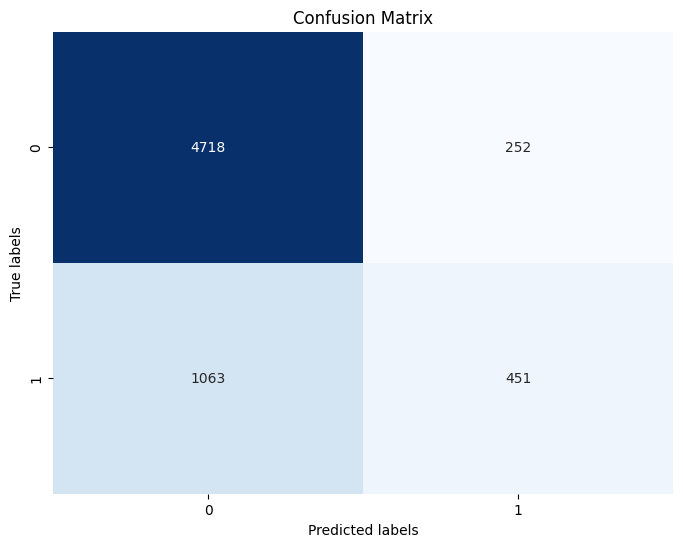

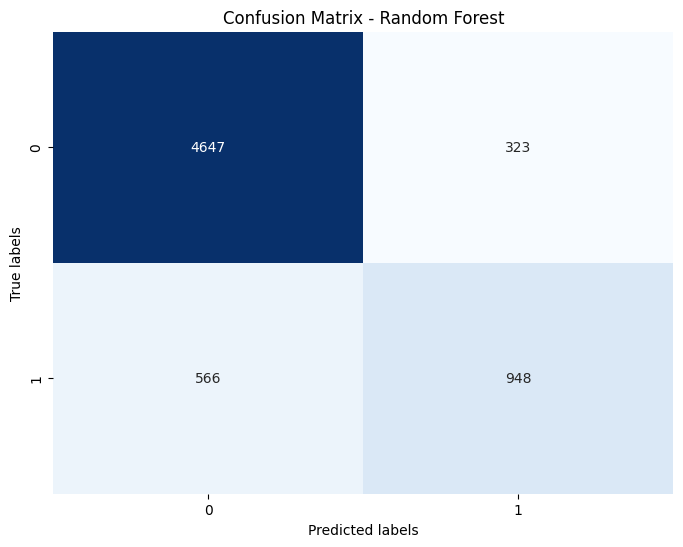

In [12]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate confusion matrix
cm = confusion_matrix(y_test, naive_bayes_pred)
print(cm)
# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()

# Confusion Matrix for Random Forest Classifier
confusion_matrix_rf = confusion_matrix(y_test, random_forest_pred)

# Plot confusion matrix for Random Forest Classifier
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix_rf, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix - Random Forest')
plt.show()